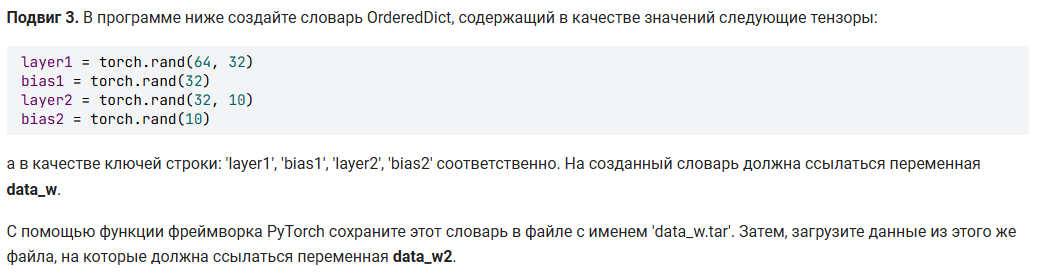

In [12]:
import torch
from collections import OrderedDict

# эти тензоры в программе не менять
layer1 = torch.rand(64, 32)
bias1 = torch.rand(32)
layer2 = torch.rand(32, 10)
bias2 = torch.rand(10)

# здесь продолжайте программу
data_w = OrderedDict()
data_w['layer1'] = layer1
data_w['bias1'] = bias1
data_w['layer2'] = layer2
data_w['bias2'] = bias2
torch.save(data_w, 'data_w.tar')
data_w2 = torch.load('data_w.tar')

OrderedDict([('layer1',
              tensor([[0.5859, 0.2476, 0.3795,  ..., 0.4526, 0.0603, 0.0742],
                      [0.3052, 0.8064, 0.4348,  ..., 0.5885, 0.7001, 0.6225],
                      [0.9893, 0.7974, 0.7045,  ..., 0.5895, 0.1445, 0.2786],
                      ...,
                      [0.0537, 0.7637, 0.0973,  ..., 0.9545, 0.6928, 0.0504],
                      [0.5590, 0.1111, 0.7545,  ..., 0.1382, 0.3137, 0.3319],
                      [0.4771, 0.1945, 0.3046,  ..., 0.1379, 0.2830, 0.4792]])),
             ('bias1',
              tensor([0.5285, 0.3101, 0.4376, 0.2268, 0.2736, 0.7056, 0.5569, 0.7112, 0.9306,
                      0.9159, 0.3260, 0.3749, 0.8163, 0.7150, 0.1347, 0.3829, 0.6434, 0.6782,
                      0.4785, 0.3140, 0.1185, 0.9899, 0.2358, 0.0499, 0.5633, 0.2813, 0.2209,
                      0.4673, 0.4193, 0.1205, 0.8416, 0.1104])),
             ('layer2',
              tensor([[0.5386, 0.3518, 0.2008, 0.8240, 0.0505, 0.5023, 0.2450, 0.778

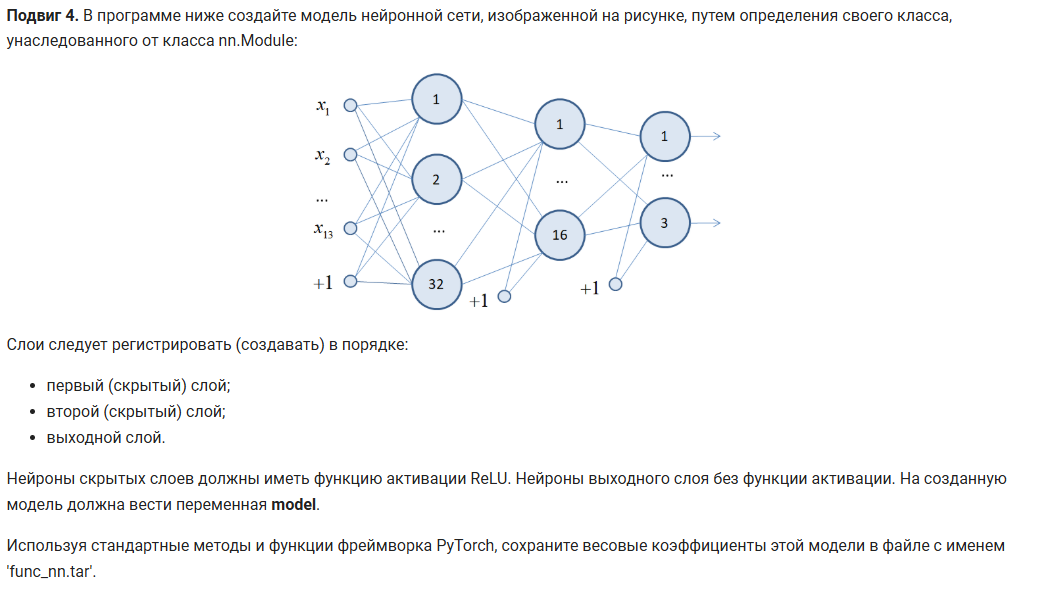

In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MyNet(nn.Module):
    def __init__(self, inp=13, hl1=32, hl2=16, out=3):
        super().__init__()
        self.first_layer = nn.Linear(inp, hl1)
        self.second_layer = nn.Linear(hl1, hl2)
        self.third_layer = nn.Linear(hl2, out)
        self.activation = F.relu

    def forward(self, x):
        x = self.first_layer(x)
        x = self.activation(x)
        x = self.second_layer(x)
        x = self.activation(x)
        x = self.third_layer(x)
        return x

model = MyNet()
torch.save(model.state_dict(), 'func_nn.tar')
    


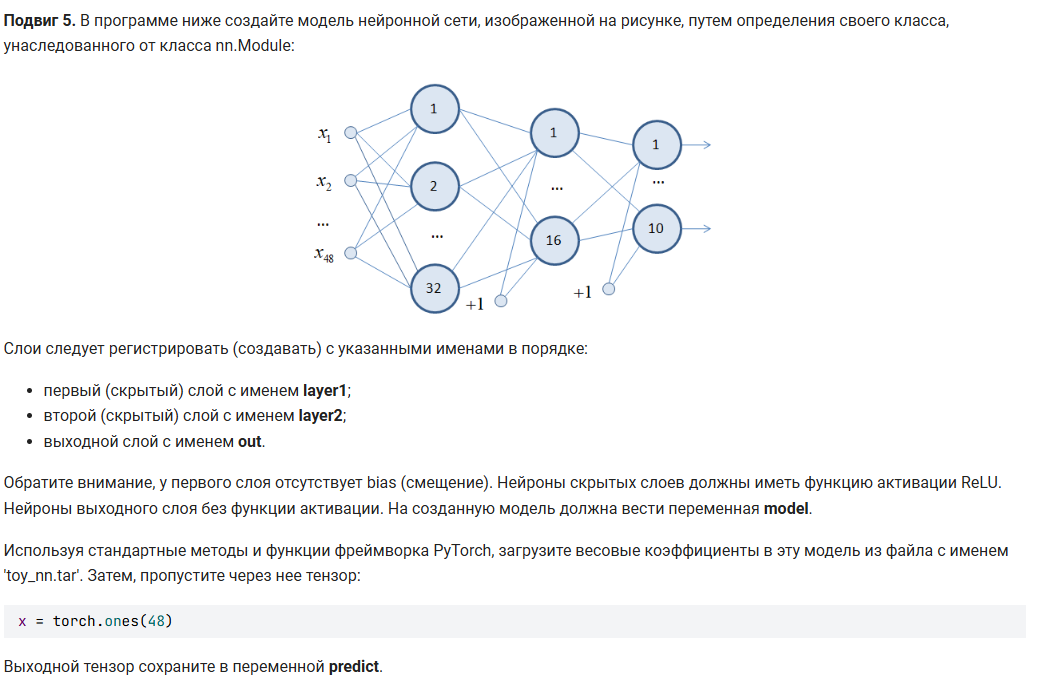

In [35]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MyNet(nn.Module):
    def __init__(self, inp=48, hl1=32, hl2=16, out=10):
        super().__init__()
        self.layer1 = nn.Linear(inp, hl1, bias=False)
        self.layer2 = nn.Linear(hl1, hl2)
        self.out = nn.Linear(hl2, out)
        self.activation = F.relu

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.layer2(x)
        x = self.activation(x)
        x = self.out(x)
        return x

model = MyNet()
torch.save(model.state_dict(), 'toy_nn.tar')
weights = torch.load('toy_nn.tar', weights_only=True)
model.load_state_dict(weights)
x = torch.ones(48)
predict = model(x)
predict


tensor([-0.1313,  0.3454, -0.2007,  0.3421, -0.0541, -0.0240, -0.1402,  0.0297,
        -0.0214,  0.0516], grad_fn=<ViewBackward0>)

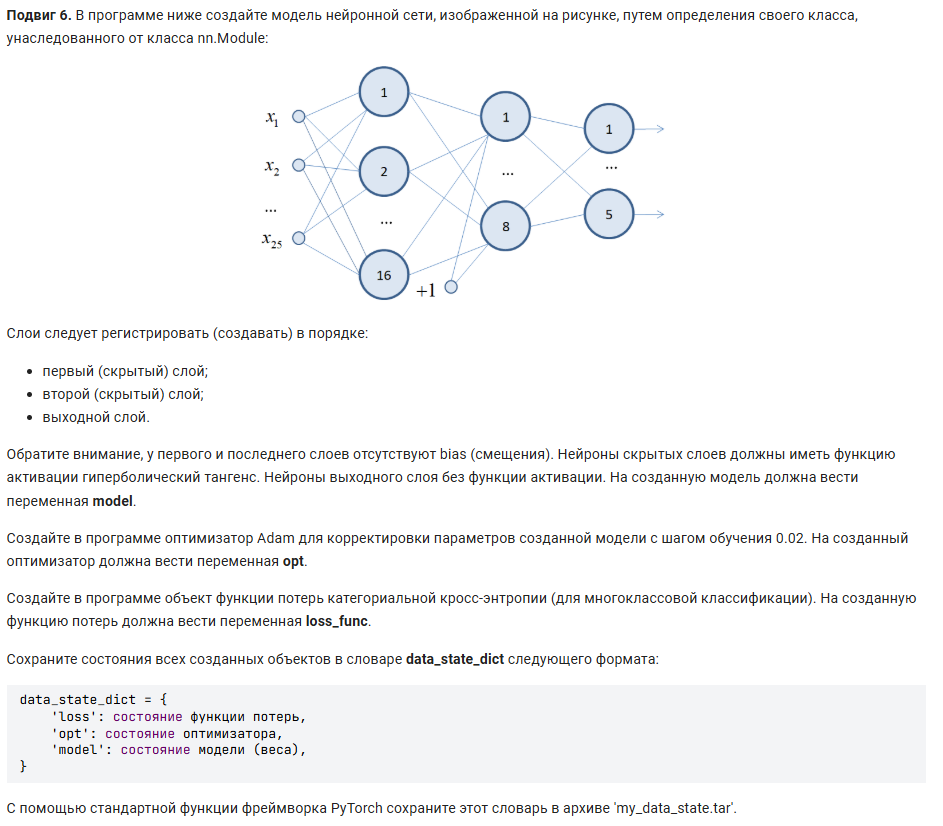

In [39]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

class MyNet(nn.Module):
    def __init__(self, inp=25, hl1=16, hl2=8, out=5):
        super().__init__()
        self.layer1 = nn.Linear(inp, hl1, bias=False)
        self.layer2 = nn.Linear(hl1, hl2)
        self.out = nn.Linear(hl2, out, bias=False)
        self.activation = F.tanh

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.layer2(x)
        x = self.activation(x)
        x = self.out(x)
        return x



model = MyNet()
opt = torch.optim.Adam(params=model.parameters())

loss_func = torch.nn.CrossEntropyLoss()

data_state_dict = {
    'loss': loss_func.state_dict(),
    'opt': opt.state_dict(),
    'model': model.state_dict(),
}

torch.save(data_state_dict,  'my_data_state.tar')

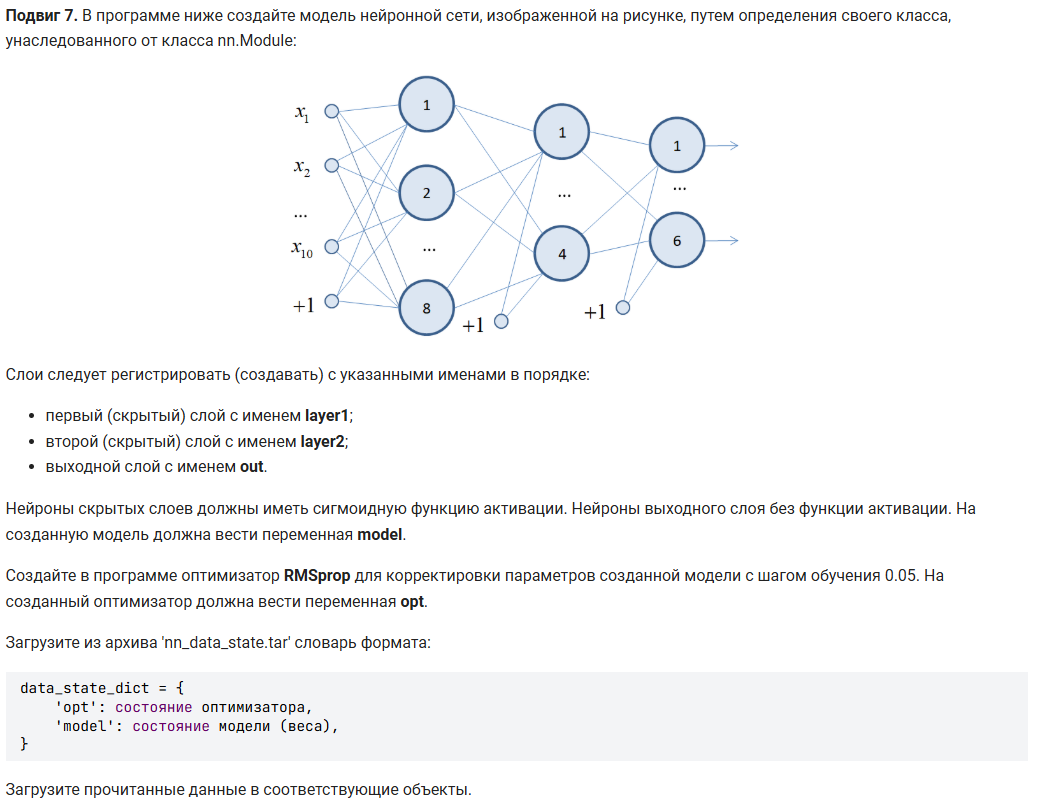

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

class MyNet(nn.Module):
    def __init__(self, inp=10, hl1=8, hl2=4, out=6):
        super().__init__()
        self.layer1 = nn.Linear(inp, hl1)
        self.layer2 = nn.Linear(hl1, hl2)
        self.out = nn.Linear(hl2, out)
        self.activation = F.sigmoid

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.layer2(x)
        x = self.activation(x)
        x = self.out(x)
        return x



model = MyNet()
opt = torch.optim.RMSprop (params=model.parameters(), lr=0.05)

loss_func = torch.nn.CrossEntropyLoss()

nn_data_state = torch.load('nn_data_state.tar')

model.load_state_dict(nn_data_state['model'])
opt.load_state_dict(nn_data_state['opt'])


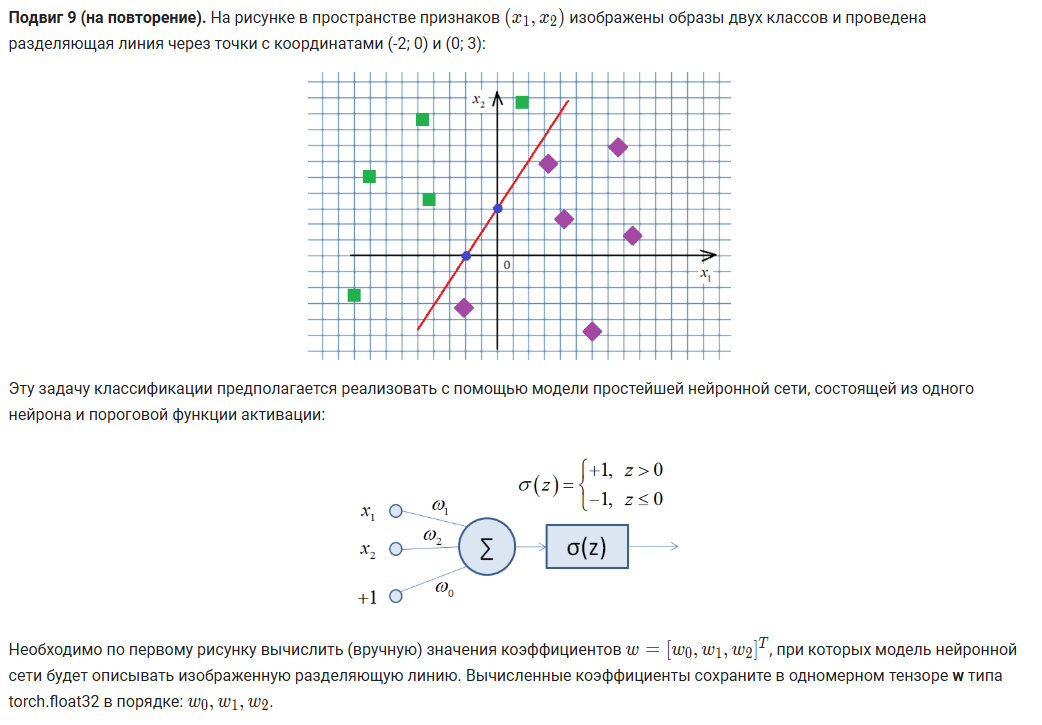